# Sentiment analysis
## Data preparation


In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
from transformers import pipeline
from tqdm import tqdm
import html

df = pd.DataFrame({
    "post_id": range(1, 11),
    "text": [
        "Nuclear energy is amazing! Clean, reliable power that can help fight climate change.",
        "I am terrified of nuclear accidents. The risks are simply too high.",
        "The government announced plans to build two new nuclear power plants by 2035.",
        "Nuclear power is one of the best solutions to reduce carbon emissions!",
        "Nuclear waste is a huge problem. We still don't have a good long-term solution.",
        "Nuclear energy provides reliable electricity, but the construction costs are enormous.",
        "I love the idea of clean nuclear energy, but safety concerns still worry me.",
        "A new study examines the economic impacts of nuclear power generation.",
        "Building more nuclear plants is a terrible waste of taxpayer money!",
        "Exciting news! New nuclear reactor technology could make clean energy more affordable."
    ]
})

df

,post_id,text
0,1,"Nuclear energy is amazing! Clean, reliable pow..."
1,2,I am terrified of nuclear accidents. The risks...
2,3,The government announced plans to build two ne...
3,4,Nuclear power is one of the best solutions to ...
4,5,Nuclear waste is a huge problem. We still don'...
5,6,"Nuclear energy provides reliable electricity, ..."
6,7,"I love the idea of clean nuclear energy, but s..."
7,8,A new study examines the economic impacts of n...
8,9,Building more nuclear plants is a terrible was...
9,10,Exciting news! New nuclear reactor technology ...


## Lexical, rule-based
VADER (Valence Aware Dictionary and sEntiment Reasoner)

In [11]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Initialize VADER
analyzer = SentimentIntensityAnalyzer()

In [13]:
# try it on a single sentence

text = "Nuclear energy is amazing! Clean, reliable power!"

scores = analyzer.polarity_scores(text)

print(scores)

{'neg': 0.0, 'neu': 0.303, 'pos': 0.697, 'compound': 0.8475}


VADER returns four scores:
- pos:	Proportion of text classified as positive
- neu:	Proportion of text classified as neutral
- neg:	Proportion of text classified as negative
- compound:	Overall normalized sentiment score, from -1 to +1

The compound score is generally used for sentiment classification.

Common thresholds:
- Positive: compound ≥ 0.05
- Negative: compound ≤ -0.05
- Neutral: -0.05 < compound < 0.05

In [14]:
# Apply VADER to each post
sentiment_scores = df["text"].apply(analyzer.polarity_scores)

# Convert results into a DataFrame
scores_df = pd.DataFrame(sentiment_scores.tolist())

# Add scores to the original DataFrame
df = pd.concat(
    [df.reset_index(drop=True), scores_df],
    axis=1
)

df.head()

,post_id,text,neg,neu,pos,compound
0,1,"Nuclear energy is amazing! Clean, reliable pow...",0.117,0.360,0.522,0.8398
1,2,I am terrified of nuclear accidents. The risks...,0.483,0.517,0.000,-0.8126
2,3,The government announced plans to build two ne...,0.000,1.000,0.000,0.0000
3,4,Nuclear power is one of the best solutions to ...,0.000,0.618,0.382,0.7345
4,5,Nuclear waste is a huge problem. We still don'...,0.368,0.418,0.214,-0.5116


In [15]:
# Classify each post: We can use the compound scores to classify posts as positive, negative, or neutral.
def classify_sentiment(score):
    if score >= 0.05:
        return "positive"
    elif score <= -0.05:
        return "negative"
    else:
        return "neutral"

df["sentiment_vader"] = df["compound"].apply(classify_sentiment)

# View results
df[["post_id", "text", "compound", "sentiment_vader"]]

,post_id,text,compound,sentiment_vader
0,1,"Nuclear energy is amazing! Clean, reliable pow...",0.8398,positive
1,2,I am terrified of nuclear accidents. The risks...,-0.8126,negative
2,3,The government announced plans to build two ne...,0.0000,neutral
3,4,Nuclear power is one of the best solutions to ...,0.7345,positive
4,5,Nuclear waste is a huge problem. We still don'...,-0.5116,negative
5,6,"Nuclear energy provides reliable electricity, ...",0.1406,positive
6,7,"I love the idea of clean nuclear energy, but s...",0.5927,positive
7,8,A new study examines the economic impacts of n...,0.0000,neutral
8,9,Building more nuclear plants is a terrible was...,-0.7345,negative
9,10,Exciting news! New nuclear reactor technology ...,0.8070,positive


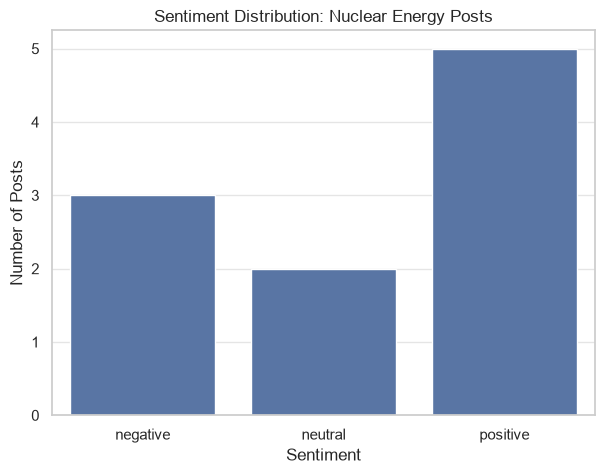

In [9]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sentiment_vader",
    order=["negative", "neutral", "positive"]
)

plt.title("Sentiment Distribution: Nuclear Energy Posts")
plt.xlabel("Sentiment")
plt.ylabel("Number of Posts")

plt.show()

## Transformer

In [19]:
# Analyze text
results = classifier(df['text'].tolist())

df["label"] = [r["label"] for r in results]
df["sentiment_score"] = [r["score"] for r in results]

df['sentiment_transformer'] = df['label'].apply(
    lambda x: "negative" if x == 'LABEL_0' else "neutral" if x=="LABEL_1" else "positive"
)

df

,post_id,text,neg,neu,pos,compound,sentiment_vader,label,sentiment_score,sentiment_transformer
0,1,"Nuclear energy is amazing! Clean, reliable pow...",0.117,0.360,0.522,0.8398,positive,LABEL_2,0.960077,positive
1,2,I am terrified of nuclear accidents. The risks...,0.483,0.517,0.000,-0.8126,negative,LABEL_0,0.961768,negative
2,3,The government announced plans to build two ne...,0.000,1.000,0.000,0.0000,neutral,LABEL_1,0.793891,neutral
3,4,Nuclear power is one of the best solutions to ...,0.000,0.618,0.382,0.7345,positive,LABEL_2,0.901988,positive
4,5,Nuclear waste is a huge problem. We still don'...,0.368,0.418,0.214,-0.5116,negative,LABEL_0,0.906624,negative
5,6,"Nuclear energy provides reliable electricity, ...",0.000,0.866,0.134,0.1406,positive,LABEL_0,0.500153,negative
6,7,"I love the idea of clean nuclear energy, but s...",0.171,0.399,0.430,0.5927,positive,LABEL_1,0.457401,neutral
7,8,A new study examines the economic impacts of n...,0.000,1.000,0.000,0.0000,neutral,LABEL_1,0.910565,neutral
8,9,Building more nuclear plants is a terrible was...,0.408,0.592,0.000,-0.7345,negative,LABEL_0,0.957683,negative
9,10,Exciting news! New nuclear reactor technology ...,0.000,0.520,0.480,0.8070,positive,LABEL_2,0.980951,positive


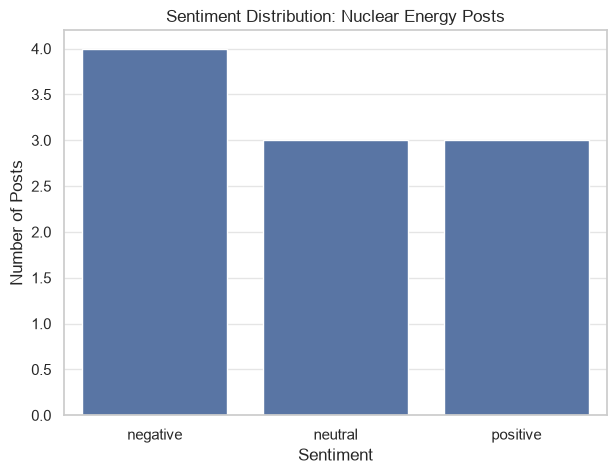

In [20]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sentiment_transformer",
    order=["negative", "neutral", "positive"]
)

plt.title("Sentiment Distribution: Nuclear Energy Posts")
plt.xlabel("Sentiment")
plt.ylabel("Number of Posts")

plt.show()

<Axes: xlabel='sentiment', ylabel='count'>

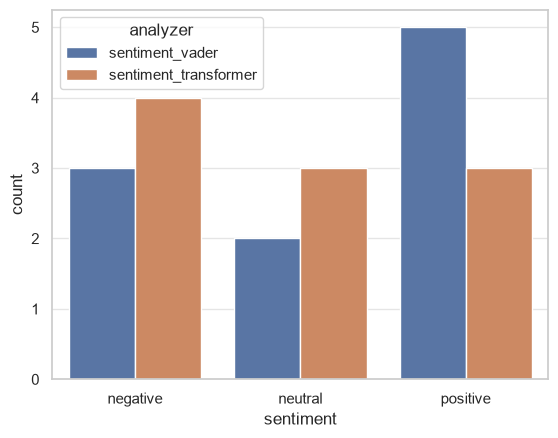

In [22]:

sns.countplot(
    data=df.melt(id_vars="post_id", value_vars=["sentiment_vader", 'sentiment_transformer'],
                 value_name="sentiment", var_name='analyzer'),
    x='sentiment', hue='analyzer',
    order=["negative", "neutral", "positive"]
)


In [23]:
df['compare'] = (df['sentiment_vader'] == df['sentiment_transformer']).astype(int)